In [101]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

## Step 1: Loading pre-flood and during-flood images

In [102]:
before_bgr = cv2.imread('floodingindianepal_20260920_before.jpg')
after_bgr = cv2.imread('floodingindianepal_20260929_after.jpg')

In [103]:
# Ensuring both images have same dimensions
after_bgr = cv2.resize(after_bgr, (before_bgr.shape[1], before_bgr.shape[0]))

In [104]:
# Converting BGR to RGB
before_rgb = cv2.cvtColor(before_bgr, cv2.COLOR_BGR2RGB)
after_rgb = cv2.cvtColor(after_bgr, cv2.COLOR_BGR2RGB)

In [105]:
def show_images(before_flood, after_flood):
  fig, axes = plt.subplots(1, 2, figsize=(10, 5))

  axes[0].imshow(before_flood)
  axes[0].set_title('Before Flood - September 20, 2026')
  axes[0].axis('off')

  axes[1].imshow(after_flood)
  axes[1].set_title('After Flood - September 29, 2026')
  axes[1].axis('off')

  plt.tight_layout
  plt.show()

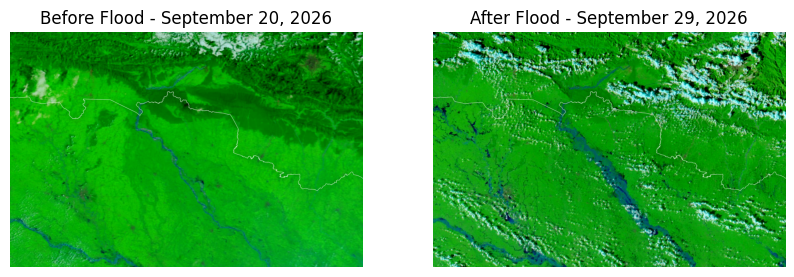

In [106]:
# Image load check
show_images(before_rgb, after_rgb)

## Step 2: Extracting water masks and finding newly flooded pixels

In [107]:
b_bef, g_bef, r_bef = cv2.split(before_bgr.astype(float))
b_aft, g_aft, r_aft = cv2.split(after_bgr.astype(float))

new_flood = ((g_bef - g_aft) > 35) & (r_aft < 70) & (b_aft > 30)
new_flood_mask = np.where(new_flood, 255, 0).astype(np.uint8)

# 3. Clean up speckle noise
kernel = np.ones((3, 3), np.uint8)
new_flood_mask = cv2.morphologyEx(new_flood_mask, cv2.MORPH_OPEN, kernel)
new_flood_mask = cv2.morphologyEx(new_flood_mask, cv2.MORPH_CLOSE, kernel)

## Step 3: Calculating flood expansion percentage

In [109]:
expansion_pct = (np.count_nonzero(new_flood_mask) / new_flood_mask.size) * 100
print(f"Newly Inundated Area: {expansion_pct:.2f}% of frame")

Newly Inundated Area: 2.08% of frame


## Step 4: Highlighting newly flooded areas in red on the post-flood image

In [110]:
# Ensure RGB versions match the current resized BGR images
overlay = after_rgb.copy()
overlay[new_flood_mask > 0] = [255, 0, 0]
blended = cv2.addWeighted(after_rgb, 0.35, overlay, 0.65, 0)

## Step 5: Plotting 3-panel comparison

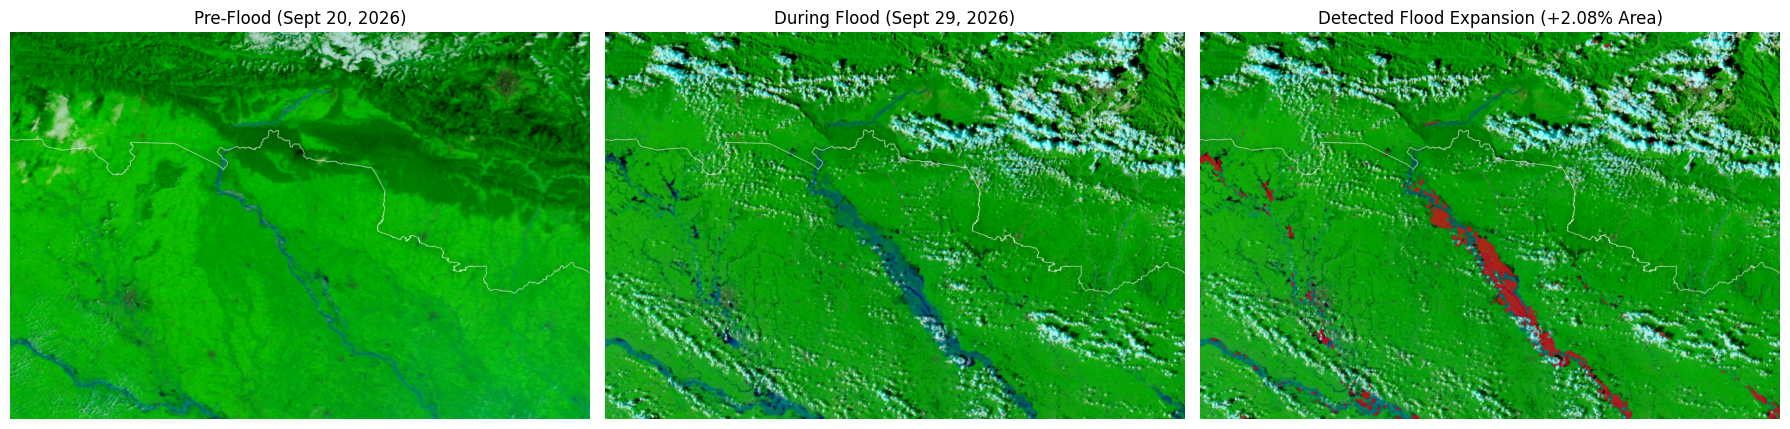

In [111]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(before_rgb)
axes[0].set_title("Pre-Flood (Sept 20, 2026)")
axes[0].axis("off")

axes[1].imshow(after_rgb)
axes[1].set_title("During Flood (Sept 29, 2026)")
axes[1].axis("off")

axes[2].imshow(blended)
axes[2].set_title(f"Detected Flood Expansion (+{expansion_pct:.2f}% Area)")
axes[2].axis("off")

plt.tight_layout()
plt.savefig("gandak_flood_change_detection.png", dpi=200)
plt.show()